# Electrode-pair polarity check, 3-fish recording (2024-10-15T14_12_25)

The mirror-symmetry test of `electrode_polarity_check.ipynb` (4-fish recordings of 2024-02-20: pairs 2 and 5 reversed) and
`electrode_polarity_check_2fish.ipynb` (2-fish recording of 2024-02-13: pair 2 not reversed, pair 5 untested), on the 3-fish recording
of `data/3_fish_silent`, in which **the smallest fish (C, ZEUS label 0) is the emitter**: the test uses that fish.

**Logic.** Neighbouring pairs a and b along the tank wall have one electrode each at a shared spot (a tank corner, or the middle
of a wall). When the emitting fish lies on the line that mirrors pair a onto pair b, with one end at that spot, the two pair voltages
must have the **same** sign if the two electrodes at the spot carry the same label (both − or both +), and **opposite** signs
otherwise. The unknown sign of the EOD cancels; nothing is fitted and no recorded sign is changed. The model is only an illustration.

**Selection**: unchanged functions and thresholds of the 4-fish notebook, applied to fish C; the mask band is also given at 73 px
(the ZEUS masks include the pectoral fins, see the 2-fish notebook).

**Data:** EODs and keypoints `Assigned_Data_3fish_2024-10-15T14_12_25.csv` (fish A, B, C = ZEUS labels 1, 2, 0; the sample columns
`electrode_<pair>_t_m12 … t_p12` are renamed `electrode_<pair>_time_1 … 25`), ZEUS masks
`elephantnose_20241015T141225_tracking_final.pkl`. Sampling rate: no raw file for this recording, **50 kHz assumed** (as in the 2-fish
recording; it only sets the time axis of the trace plots). **Electrodes**: the 2024-02-13 file is the main one (its positions sit on
the electrodes seen in this video); the 2024-10-23 file (positions a few px off, pair 5 labelled the other way round) is tested too.

In [1]:
import re
import pickle
import mask_metrics as mm                         # ZEUS crop unpacking (sets the Agg backend...)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from scipy.ndimage import distance_transform_edt
from compute_electric_field import mask_to_grid
from eod_assign import (load_electrode_pairs, eod_sample_count, eods_with_masks, recorded_pair_traces_all,
                        recorded_pair_traces, eod_phase_samples, normalize_peak, candidate_field, pair_voltages,
                        iter_mgz_frames)
from midline_methods import fish_midline_with_head
from io_utils import rle_decode

ELECTRODES_CSV = 'data/electrodes_signed_px_coord_2024-02-13.csv'
P, FS = 912, 50000.0                            # no raw file for this recording: 50 kHz assumed
N, delta_h = 200, 0.5
MAT = dict(sigma_water=1.0, eps_water=0.0, sigma_interior=200.0, eps_interior=0.0, sigma_skin=0.05, eps_skin=2.7e-6)

pairs = load_electrode_pairs(ELECTRODES_CSV, P)
pair_ids = [pid for pid, _, _ in pairs]

def mask_under_keypoint(row, fm, k):
    '''Index of the mask nearest tracked fish k's middle keypoint in a df_eod row (the mask under it, if any).'''
    p = np.array([row[f'middle_y_{k}'], row[f'middle_x_{k}']])
    return int(np.argmin([np.min(np.linalg.norm(np.argwhere(m) - p, axis=1)) if m.any() else np.inf for m in fm]))

def load_recording(name, eod_csv, n_frames, frame_masks, mask_of=mask_under_keypoint):
    '''One recording: its EODs, their rank-1 patterns and the tracked keypoints.
       frame_masks(frames) -> {frame: (n_fish, P, P) masks}; mask_of(row, frame masks, fish id) -> index of that fish's mask.'''
    df_all = eod_csv if isinstance(eod_csv, pd.DataFrame) else pd.read_csv(eod_csv, low_memory=False)
    df = eods_with_masks(df_all, n_frames)
    n_samp = eod_sample_count(df)
    V_all = recorded_pair_traces_all(df, pair_ids, n_samp)
    U_, s_, _ = np.linalg.svd(np.nan_to_num(V_all), full_matrices=False)
    ids = sorted(m.group(1) for c in df.columns for m in [re.match(r'middle_x_(\w+)$', c)] if m)
    kp = {k: [df[[f'{b}_y_{k}', f'{b}_x_{k}']].to_numpy(float) / (P - 1) for b in ('head', 'middle', 'tail')] for k in ids}
    lengths = {k: np.nanmedian(np.linalg.norm(kp[k][0] - kp[k][2], axis=1)) * (P - 1) for k in ids}
    R = dict(name=name, df=df, n_samp=n_samp, u=U_[:, :, 0] * s_[:, :1], ids=ids, kp=kp, lengths=lengths,
             big=max(lengths, key=lengths.get), frame_masks=frame_masks, mask_of=mask_of)
    print(f"{name}: {len(df)} EODs | variance in the rank-1 pattern: median "
          f"{np.median(s_[:, 0]**2 / np.sum(s_**2, axis=1)):.4f} | median head-tail length per tracked fish (px): "
          f"{ {k: round(v) for k, v in lengths.items()} } -> largest: {R['big']}")
    return R

## 1. Mirror lines and the shared spots

The mirror line of pairs a and b is the perpendicular bisector of the two pairs' midpoints (reflecting across it maps one pair
onto the other). For the corner pairs 2/3 (and 4/5) it runs along the tank diagonal. Pairs 5 and 6 lie on the same wall
with their − ends meeting in the middle of it, so their mirror line is perpendicular to that wall.

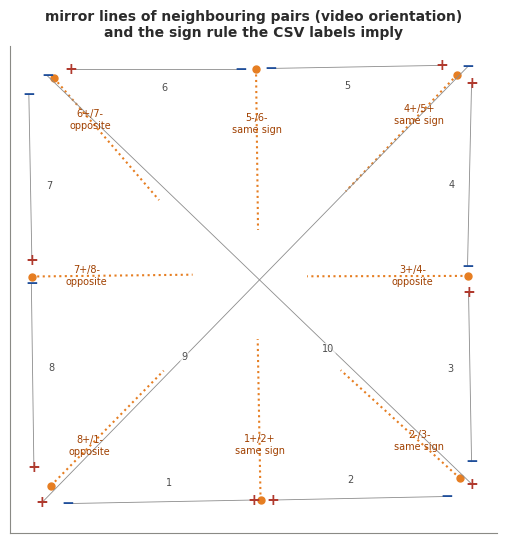

In [2]:
SPOTS = [(1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 8), (8, 1)]
ELEC = {pid: {'+': pp, '-': pm} for pid, pp, pm in pairs}

def mirror_line(pa, pb):
    '''(spot, d, labels): the point of the mirror line of pairs pa, pb next to their closest electrodes, the line's unit
       direction pointing into the tank, and the labels (of pa, of pb) of those two closest electrodes. Tank coordinates.'''
    la, lb = min(((x, y) for x in '+-' for y in '+-'), key=lambda xy: np.linalg.norm(ELEC[pa][xy[0]] - ELEC[pb][xy[1]]))
    ma, mb = 0.5 * (ELEC[pa]['+'] + ELEC[pa]['-']), 0.5 * (ELEC[pb]['+'] + ELEC[pb]['-'])
    n = (mb - ma) / np.linalg.norm(mb - ma)
    d = np.array([-n[1], n[0]]); c = 0.5 * (ma + mb)
    spot = c + ((0.5 * (ELEC[pa][la] + ELEC[pb][lb]) - c) @ d) * d
    if (0.5 - spot) @ d < 0: d = -d
    return spot, d, (la, lb)

def draw_electrodes(ax, highlight=(), colors=None):
    '''Electrodes in video orientation (x = pixel column, y = pixel row downwards).'''
    for q, pp, pm in pairs:
        hl = q in highlight; c = (colors or {}).get(q, 'm')
        ax.plot([pp[1], pm[1]], [pp[0], pm[0]], color=c if hl else '0.55', lw=2.2 if hl else 0.6, zorder=3)
        ax.text(pp[1], pp[0], '+', color='#B03A2E', fontsize=15 if hl else 11, weight='bold', ha='center', va='center', zorder=4)
        ax.text(pm[1], pm[0], '−', color='#1F4E9A', fontsize=15 if hl else 11, weight='bold', ha='center', va='center', zorder=4)
        mid = 0.5 * (pp + pm) if np.linalg.norm(pp - pm) < 1 else pp + 0.3 * (pm - pp)
        lab = mid + 0.045 * (0.5 - mid) / max(np.linalg.norm(0.5 - mid), 1e-9)
        ax.text(lab[1], lab[0], str(q), zorder=6, bbox=dict(boxstyle='round,pad=0.1', fc='w', ec='none', alpha=0.7),
                fontsize=10 if hl else 7, color=c if hl else '0.3', weight='bold' if hl else 'normal', ha='center', va='center')
    ax.set(xlim=(-0.03, 1.03), ylim=(1.03, -0.03), aspect='equal', xticks=[], yticks=[])

fig, ax = plt.subplots(figsize=(5.5, 5.5))
draw_electrodes(ax)
for pa, pb in SPOTS:
    spot, d, (la, lb) = mirror_line(pa, pb)
    end = spot + 0.35 * d
    ax.plot([spot[1], end[1]], [spot[0], end[0]], ':', color='#E67E22', lw=1.5)
    ax.plot(spot[1], spot[0], 'o', color='#E67E22', ms=5)
    t = spot + 0.12 * d
    ax.text(t[1], t[0], f'{pa}{la}/{pb}{lb}\n' + ('same sign' if la == lb else 'opposite'), fontsize=7, ha='center',
            va='center', color='#A04000')
ax.set_title('mirror lines of neighbouring pairs (video orientation)\nand the sign rule the CSV labels imply', fontsize=10)
plt.tight_layout(); plt.show()

In [3]:
BAND_MAX, EXTENT_MIN, CLEAR_MIN = 0.05, 0.85, 0.10      # CLEAR_MIN: 91 px, about half the largest fish
EV_COLS = ['pa', 'pb', 'row', 'frame', 'k', 'end', 'dist_end', 'angle', 'offset', 'other', 'u_a', 'u_b', 'same_sign', 'rule_same']
PAIR_COLORS = ('m', '#16A085')
g = np.linspace(0, 1, N)

def symmetric_events(R, pa, pb, max_end=0.18, max_angle=30.0, max_offset=0.06, min_other=0.2):
    '''EODs of recording R passing selection steps 1-3 for the spot of pairs pa, pb, with the largest fish at the spot.'''
    df, u, kp, k = R['df'], R['u'], R['kp'], R['big']
    spot, d, (la, lb) = mirror_line(pa, pb); nrm = np.array([-d[1], d[0]])
    ia, ib = pair_ids.index(pa), pair_ids.index(pb)
    top2 = np.sort(np.argsort(-np.abs(u), axis=1)[:, :2], axis=1)
    is_top = (top2 == sorted((ia, ib))).all(axis=1)
    H, Mid, T = kp[k]
    dH, dT = np.linalg.norm(H - spot, axis=1), np.linalg.norm(T - spot, axis=1)
    head_in = dH < dT
    E, O = np.where(head_in[:, None], H, T), np.where(head_in[:, None], T, H)
    axis = (O - E) / np.linalg.norm(O - E, axis=1, keepdims=True)
    angle = np.degrees(np.arccos(np.clip(axis @ d, -1, 1)))
    offset = np.max([np.abs((q - spot) @ nrm) for q in (H, Mid, T)], axis=0)
    other = np.nanmin([np.linalg.norm(q - spot, axis=1) for j in R['ids'] if j != k for q in kp[j]], axis=0)
    with np.errstate(invalid='ignore'):
        ok = is_top & (np.minimum(dH, dT) < max_end) & (angle < max_angle) & (offset < max_offset) & (other > min_other)
    return pd.DataFrame([dict(pa=pa, pb=pb, row=df.index[i], frame=int(df['Frame'].iloc[i]), k=k,
                              end='head' if head_in[i] else 'tail', dist_end=min(dH[i], dT[i]), angle=angle[i],
                              offset=offset[i], other=other[i], u_a=u[i, ia], u_b=u[i, ib],
                              same_sign=bool(np.sign(u[i, ia]) == np.sign(u[i, ib])), rule_same=la == lb)
                         for i in np.flatnonzero(ok)], columns=EV_COLS)

def along_line(mask, spot, d):
    '''(band, extent) of a mask relative to the line (spot, d): 98th percentile of its pixels' distance from the line, and
       its extent along the line (1st to 99th percentile). Tank units.'''
    q = np.argwhere(mask) / (P - 1) - spot
    s = q @ d
    return np.percentile(np.abs(q @ np.array([-d[1], d[0]])), 98), np.percentile(s, 99) - np.percentile(s, 1)

def mirror_events(R, **kw):
    '''All spots: keypoint steps, then the mask step. Returns (all keypoint-step events, events passing the mask step).'''
    ev = pd.concat([symmetric_events(R, pa, pb, **kw) for pa, pb in SPOTS], ignore_index=True)   # kw: keypoint thresholds
    ev = ev.reindex(columns=EV_COLS + ['mask', 'band', 'extent', 'largest', 'clearance', 'follows_labels'])
    if ev.empty: return ev, ev
    band, extent, largest, mask, clear = {}, {}, {}, {}, {}
    for fr, fm in R['frame_masks'](set(ev.frame)).items():
        for i in ev.index[ev.frame == fr]:
            f = mask[i] = R['mask_of'](R['df'].loc[int(ev.at[i, 'row'])], fm, R['big'])
            spot, d, _ = mirror_line(int(ev.at[i, 'pa']), int(ev.at[i, 'pb']))
            largest[i] = f == int(np.argmax([m.sum() for m in fm]))
            band[i], extent[i] = along_line(fm[f], spot, d) if fm[f].any() else (np.nan, np.nan)
            extent[i] /= R['lengths'][R['big']] / (P - 1)
            dt = distance_transform_edt(~fm[f])
            clear[i] = min((dt[m].min() for j, m in enumerate(fm) if j != f and m.any()), default=np.inf) / (P - 1)
    ev['mask'], ev['band'], ev['extent'], ev['largest'] = pd.Series(mask), pd.Series(band), pd.Series(extent), pd.Series(largest)
    ev['clearance'] = pd.Series(clear)
    ev['follows_labels'] = ev.same_sign == ev.rule_same
    return ev, ev[(ev.band <= BAND_MAX) & (ev.extent >= EXTENT_MIN) & (ev.clearance >= CLEAR_MIN)]

def spot_table(E):
    idx = pd.MultiIndex.from_tuples(SPOTS, names=['pa', 'pb'])
    lab = {s: mirror_line(*s)[2] for s in SPOTS}
    t = pd.DataFrame({'labels at spot': [f'{a}{lab[(a, b)][0]} / {b}{lab[(a, b)][1]}' for a, b in SPOTS],
                      'rule': ['same sign' if lab[s][0] == lab[s][1] else 'opposite' for s in SPOTS]}, index=idx)
    g_ = E.groupby(['pa', 'pb']) if len(E) else None
    t['EODs'] = (g_.size().reindex(idx) if g_ else pd.Series(0, idx)).fillna(0).astype(int)
    t['visits (>100 frames apart)'] = (g_.frame.apply(lambda f: int((np.diff(np.sort(f.to_numpy())) > 100).sum() + 1))
                                       .reindex(idx) if g_ else pd.Series(0, idx)).fillna(0).astype(int)
    t['follow labels'] = (g_.follows_labels.mean().reindex(idx) if g_ else pd.Series(np.nan, idx)).round(2)
    t['verdict'] = ['no symmetric fish' if n == 0 else ('labels hold' if m >= 0.9 else
                    ('labels CONTRADICTED' if m <= 0.1 else 'mixed')) for n, m in zip(t.EODs, t['follow labels'])]
    return t

def pick_examples(sym, pa, pb, n=2, min_gap=100):
    E = sym[(sym.pa == pa) & (sym.pb == pb)].assign(score=lambda x: x.band + x.dist_end + x.angle / 100 - x.clearance)
    out = []
    for _, e in E.sort_values('score').iterrows():
        if len(out) == n: break
        if all(abs(e.frame - o.frame) > min_gap for o in out): out.append(e)
    return out

def head_agrees(row, k, mid):
    '''Whether the midline's head end is nearer the row's head keypoint of fish k than its tail end is.'''
    hd = np.array([row[f'head_y_{k}'], row[f'head_x_{k}']]) / (P - 1)
    tl = np.array([row[f'tail_y_{k}'], row[f'tail_x_{k}']]) / (P - 1)
    return bool(np.linalg.norm(mid[-1] - hd) + np.linalg.norm(mid[0] - tl) < np.linalg.norm(mid[-1] - tl) + np.linalg.norm(mid[0] - hd))

def plot_example(axes, R, e, fm):
    pa, pb = int(e.pa), int(e.pb); r = int(e.row); row = R['df'].loc[r]
    f = int(e['mask']); colors = dict(zip((pa, pb), PAIR_COLORS))
    mids = [fish_midline_with_head(m, n_ctrl=101)['midline'] if m.sum() >= 50 else None for m in fm]
    phi = candidate_field(fm, f, mids[f], N, delta_h, MAT).real
    a = normalize_peak(pair_voltages(phi, pairs, N))
    V = recorded_pair_traces(row, pair_ids, R['n_samp'])
    p1, p2 = eod_phase_samples(V)
    b = normalize_peak(V[:, p1])
    ia, ib = pair_ids.index(pa), pair_ids.index(pb)
    spot, d, _ = mirror_line(pa, pb)
    t_ms = np.arange(R['n_samp']) / FS * 1e3

    ax = axes[0]
    vmax = np.percentile(np.abs(phi), 99)
    ax.imshow(phi, origin='upper', extent=[0, 1, 1, 0], cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    for j, m in enumerate(fm):
        if m.any():
            ax.contour(g, g, mask_to_grid(m, N).astype(float), levels=[0.5], colors=['k' if j == f else '0.35'],
                       linewidths=2.0 if j == f else 0.8)
    ax.plot(mids[f][-1][1], mids[f][-1][0], 'o', color='gold', ms=7, mec='k', mew=0.8, zorder=5, label='head')
    ax.plot(mids[f][0][1], mids[f][0][0], 's', color='w', ms=6, mec='k', mew=0.8, zorder=5, label='tail')
    end = spot + 0.45 * d
    ax.plot([spot[1], end[1]], [spot[0], end[0]], ':', color='k', lw=1, zorder=3, label=f'{pa}/{pb} mirror line')
    draw_electrodes(ax, (pa, pb), colors)
    big = 'emitter'
    ax.set_title(f'frame {int(e.frame)}: {big} ({R["big"]}), {e.end} at the {pa}/{pb} spot\n'
                 f'body within {e.band * (P - 1):.0f} px of the line, nearest other fish {e.clearance * (P - 1):.0f} px; '
                 f'model, head-positive current', fontsize=9)
    ax.legend(loc='center', fontsize=7, framealpha=0.8)

    ax = axes[1]
    for i, q in enumerate(pair_ids):
        hl = q in colors
        ax.plot(t_ms, V[i] / np.max(np.abs(V)), color=colors.get(q, '0.75'), lw=2.2 if hl else 0.9,
                label=f'pair {q}' if hl else ('other pairs' if i == 0 else None), zorder=3 if hl else 2)
    for p, lab in ((p1, 'P1'), (p2, 'P2')):
        ax.axvline(t_ms[p], color='k', ls='--' if lab == 'P1' else ':', lw=0.8); ax.text(t_ms[p], 1.08, lab, ha='center', fontsize=9)
    ax.axhline(0, color='0.85', lw=0.5)
    ax.set(xlabel='time (ms, 50 kHz assumed)', ylabel='recorded voltage (max |V| = 1)', ylim=(-1.15, 1.2), title=f'recorded EOD (df_eod row {r})')
    ax.legend(fontsize=8, loc='lower left')

    ax = axes[2]
    x = np.arange(len(pair_ids)); w = 0.38
    ax.bar(x - w / 2, b, w, color='k', label=f'recorded at P1 (t = {t_ms[p1]:.2f} ms)')
    ax.bar(x + w / 2, a, w, color='#E67E22', label='model (head-positive current)')
    for q, c in colors.items():
        ax.axvspan(pair_ids.index(q) - 0.5, pair_ids.index(q) + 0.5, color=c, alpha=0.12, zorder=0)
    ax.axhline(0, color='k', lw=0.5)
    ax.set(xticks=x, xticklabels=pair_ids, xlabel='electrode pair', ylabel='voltage (max |v| = 1)', ylim=(-1.25, 1.25),
           title=f'pairs {pa} / {pb}: recorded {b[ia]:+.2f} / {b[ib]:+.2f},  model {a[ia]:+.2f} / {a[ib]:+.2f}')
    ax.legend(fontsize=8, loc='lower left')
    return dict(recording=R['name'], row=r, frame=int(e.frame), pairs=f'{pa}/{pb}', fish=R['big'], end=e.end,
                head_matches_keypoints=head_agrees(row, R['big'], mids[f]),
                rec_a=round(b[ia], 2), rec_b=round(b[ib], 2), model_a=round(a[ia], 2), model_b=round(a[ib], 2))

def show_spot(R, sym, pa, pb, title):
    ex = pick_examples(sym, pa, pb)
    if not ex:
        print(f'{R["name"]}, pairs {pa}/{pb}: no symmetric EOD of the largest fish'); return []
    fms = R['frame_masks']({int(e.frame) for e in ex})
    fig, axes = plt.subplots(len(ex), 3, figsize=(17, 5.6 * len(ex)), squeeze=False,
                             gridspec_kw=dict(width_ratios=[1, 1.1, 1.3]))
    out = [plot_example(ax_row, R, e, fms[int(e.frame)]) for e, ax_row in zip(ex, axes)]
    fig.suptitle(f'{R["name"]}: {title} (emitter {R["big"]}, {len(ex)} visit{"s" if len(ex) > 1 else ""})', fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.95]); plt.show()
    return out

TITLE_23 = 'fish on the 2/3 mirror line (tank diagonal): 2− and 3− share the corner, so pairs 2 and 3 must have the same sign'
TITLE_56 = 'fish on the 5/6 mirror line (perpendicular to the wall): 5− and 6− meet mid-wall, so pairs 5 and 6 must have the same sign'
shown = []

## 2. Recording 2024-10-15T14_12_25 (3 fish, fish C emits): symmetric EODs at every spot, 2024-02-13 electrodes

In [4]:
DATA = 'data/3_fish_silent'
EOD_CSV = f'{DATA}/Assigned_Data_3fish_2024-10-15T14_12_25.csv'
TRACK_PKL = f'{DATA}/elephantnose_20241015T141225_tracking_final.pkl'
EMITTER_ID, EMITTER_LABEL = 'C', 0                       # SLEAP fish C = ZEUS label 0, the smallest fish
LAYOUTS = {'2024-02-13': 'data/electrodes_signed_px_coord_2024-02-13.csv', '2024-10-23': 'data/electrodes_signed_px_coord_2024-10-23.csv'}

def use_layout(csv):
    '''Make `csv` the electrode file of every function above (pairs, pair_ids, ELEC are module globals).'''
    global pairs, pair_ids, ELEC
    pairs = load_electrode_pairs(csv, P); pair_ids = [pid for pid, _, _ in pairs]
    ELEC = {pid: {'+': pp, '-': pm} for pid, pp, pm in pairs}

eod = pd.read_csv(EOD_CSV, low_memory=False)
samp = {}
for c in eod.columns:
    m = re.match(r'electrode_(\d+)_t_(m|p)?(\d+)$', c)
    if m: samp[c] = (int(m.group(1)), (-1 if m.group(2) == 'm' else 1) * int(m.group(3)))
lo = min(s for _, s in samp.values())
eod = eod.rename(columns={c: f'electrode_{p}_time_{s - lo + 1}' for c, (p, s) in samp.items()})
keep = ['Frame', 'Time', 'RelativeTime'] + [c for c in eod.columns if re.match(r'(head|middle|tail)_[xy]_[ABC]$|electrode_\d+_time_\d+$', c)]
eod = eod[keep]

with open(TRACK_PKL, 'rb') as fh:
    trk = pickle.load(fh)
assert trk['shape'][0] == P

def zeus_frame_masks(frames):
    '''{frame: (3, P, P) masks}, index = ZEUS label (1 = largest, 2 = middle, 0 = smallest fish, the emitter).'''
    out = {}
    for k in sorted(frames):
        fm = np.zeros((3, P, P), bool)
        for l, packed, (y0, y1, x0, x1) in zip(*(trk['frames'][k][c] for c in ('labels', 'masks', 'boxes'))):
            if l in (0, 1, 2): fm[l, y0:y1, x0:x1] = mm.unpack_crop(packed, (y0, y1, x0, x1))
        out[k] = fm
    return out

use_layout(LAYOUTS['2024-02-13'])
R4 = load_recording('2024-10-15T14_12_25 (3 fish)', eod, len(trk['frames']), zeus_frame_masks)
R4['big'] = EMITTER_ID                                   # the test follows the emitter, not the largest fish
ev4, sym4 = mirror_events(R4)
BAND_WIDE = 0.08
sym4w = ev4[(ev4.band <= BAND_WIDE) & (ev4.extent >= EXTENT_MIN) & (ev4.clearance >= CLEAR_MIN)]
print(f"{len(ev4)} EODs of fish C after the keypoint steps | after the mask step: {len(sym4)} (band 46 px), {len(sym4w)} "
      f"(band {BAND_WIDE * (P - 1):.0f} px) | fish C on mask {EMITTER_LABEL} in {(ev4['mask'] == EMITTER_LABEL).mean():.0%} of them")
tables = {'band 46 px': spot_table(sym4), f'band {BAND_WIDE * (P - 1):.0f} px': spot_table(sym4w), 'keypoint steps only': spot_table(ev4)}
display(tables[f'band {BAND_WIDE * (P - 1):.0f} px'])

2024-10-15T14_12_25 (3 fish): 19784 EODs | variance in the rank-1 pattern: median 0.9993 | median head-tail length per tracked fish (px): {'A': 159, 'B': 129, 'C': 102} -> largest: A


/var/folders/w4/p225s7cd19n0j6tss7pdl21w0000gn/T/ipykernel_91862/2123881352.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  ev = pd.concat([symmetric_events(R, pa, pb, **kw) for pa, pb in SPOTS], ignore_index=True)   # kw: keypoint thresholds


13 EODs of fish C after the keypoint steps | after the mask step: 0 (band 46 px), 2 (band 73 px) | fish C on mask 0 in 100% of them


,,labels at spot,rule,EODs,visits (>100 frames apart),follow labels,verdict
pa,pb,,,,,,
1,2,1+ / 2+,same sign,0,0,NaN,no symmetric fish
2,3,2- / 3-,same sign,0,0,NaN,no symmetric fish
3,4,3+ / 4-,opposite,0,0,NaN,no symmetric fish
4,5,4+ / 5+,same sign,0,0,NaN,no symmetric fish
5,6,5- / 6-,same sign,2,1,0.0,labels CONTRADICTED
6,7,6+ / 7-,opposite,0,0,NaN,no symmetric fish
7,8,7+ / 8-,opposite,0,0,NaN,no symmetric fish
8,1,8+ / 1-,opposite,0,0,NaN,no symmetric fish


In [5]:
for name in ('band 46 px', 'keypoint steps only'):
    print(name); display(tables[name])

band 46 px


,,labels at spot,rule,EODs,visits (>100 frames apart),follow labels,verdict
pa,pb,,,,,,
1,2,1+ / 2+,same sign,0,0,NaN,no symmetric fish
2,3,2- / 3-,same sign,0,0,NaN,no symmetric fish
3,4,3+ / 4-,opposite,0,0,NaN,no symmetric fish
4,5,4+ / 5+,same sign,0,0,NaN,no symmetric fish
5,6,5- / 6-,same sign,0,0,NaN,no symmetric fish
6,7,6+ / 7-,opposite,0,0,NaN,no symmetric fish
7,8,7+ / 8-,opposite,0,0,NaN,no symmetric fish
8,1,8+ / 1-,opposite,0,0,NaN,no symmetric fish


keypoint steps only


,,labels at spot,rule,EODs,visits (>100 frames apart),follow labels,verdict
pa,pb,,,,,,
1,2,1+ / 2+,same sign,0,0,NaN,no symmetric fish
2,3,2- / 3-,same sign,0,0,NaN,no symmetric fish
3,4,3+ / 4-,opposite,0,0,NaN,no symmetric fish
4,5,4+ / 5+,same sign,0,0,NaN,no symmetric fish
5,6,5- / 6-,same sign,2,1,0.0,labels CONTRADICTED
6,7,6+ / 7-,opposite,11,2,0.0,labels CONTRADICTED
7,8,7+ / 8-,opposite,0,0,NaN,no symmetric fish
8,1,8+ / 1-,opposite,0,0,NaN,no symmetric fish


## 3. The same test with the 2024-10-23 electrode file

Same EODs and keypoints; the mirror lines come from the October positions, and its labels differ from the February file only at pair
5 (+ and − the other way round).

In [6]:
use_layout(LAYOUTS['2024-10-23'])
ev4o, _ = mirror_events(R4)
sym4ow = ev4o[(ev4o.band <= BAND_WIDE) & (ev4o.extent >= EXTENT_MIN) & (ev4o.clearance >= CLEAR_MIN)]
tables_oct = {f'band {BAND_WIDE * (P - 1):.0f} px': spot_table(sym4ow), 'keypoint steps only': spot_table(ev4o)}
for name, t in tables_oct.items():
    print(f'2024-10-23 electrodes, {name}'); display(t)
use_layout(LAYOUTS['2024-02-13'])

/var/folders/w4/p225s7cd19n0j6tss7pdl21w0000gn/T/ipykernel_91862/2123881352.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  ev = pd.concat([symmetric_events(R, pa, pb, **kw) for pa, pb in SPOTS], ignore_index=True)   # kw: keypoint thresholds


2024-10-23 electrodes, band 73 px


,,labels at spot,rule,EODs,visits (>100 frames apart),follow labels,verdict
pa,pb,,,,,,
1,2,1+ / 2+,same sign,0,0,NaN,no symmetric fish
2,3,2- / 3-,same sign,0,0,NaN,no symmetric fish
3,4,3+ / 4-,opposite,0,0,NaN,no symmetric fish
4,5,4+ / 5-,opposite,0,0,NaN,no symmetric fish
5,6,5+ / 6-,opposite,2,1,1.0,labels hold
6,7,6+ / 7-,opposite,0,0,NaN,no symmetric fish
7,8,7+ / 8-,opposite,0,0,NaN,no symmetric fish
8,1,8+ / 1-,opposite,0,0,NaN,no symmetric fish


2024-10-23 electrodes, keypoint steps only


,,labels at spot,rule,EODs,visits (>100 frames apart),follow labels,verdict
pa,pb,,,,,,
1,2,1+ / 2+,same sign,0,0,NaN,no symmetric fish
2,3,2- / 3-,same sign,0,0,NaN,no symmetric fish
3,4,3+ / 4-,opposite,0,0,NaN,no symmetric fish
4,5,4+ / 5-,opposite,0,0,NaN,no symmetric fish
5,6,5+ / 6-,opposite,2,1,1.0,labels hold
6,7,6+ / 7-,opposite,11,2,0.0,labels CONTRADICTED
7,8,7+ / 8-,opposite,0,0,NaN,no symmetric fish
8,1,8+ / 1-,opposite,0,0,NaN,no symmetric fish


## 4. Examples at every spot, with the model (2024-02-13 electrodes)

Two frames per spot (two visits at least 100 frames apart) where available, from the EODs passing the 73 px band, chosen as in the
4-fish notebook. Each row: the model potential with the fish (emitter outlined thick, video orientation), the recorded traces of all 10
pairs, and model vs recording at the EOD's first phase P1, each scaled to max |v| = 1. The model uses the current `multipole_sources`
(sink 5% of the body length from the tail tip) and the electrode labels of the file; no sign is changed anywhere.

pairs 1/2: no symmetric EOD of fish C
pairs 2/3: no symmetric EOD of fish C
pairs 3/4: no symmetric EOD of fish C
pairs 4/5: no symmetric EOD of fish C


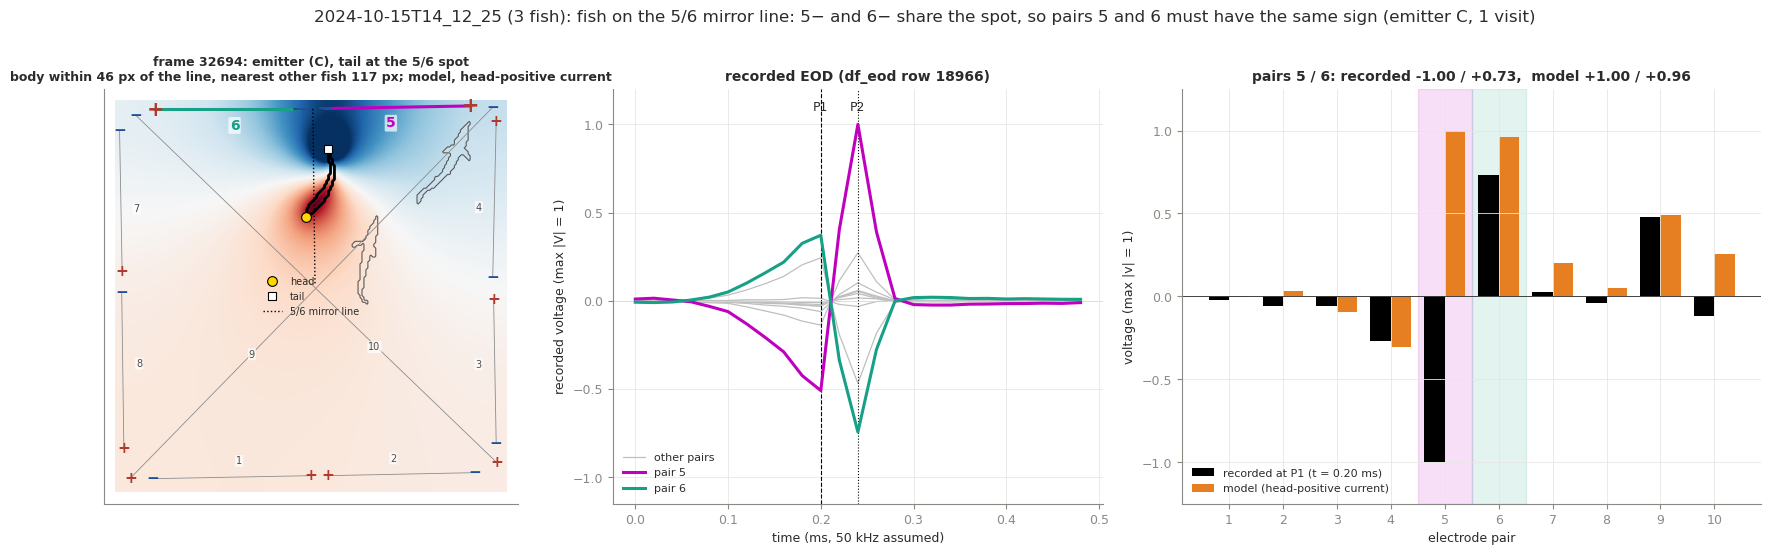

pairs 6/7: no symmetric EOD of fish C
pairs 7/8: no symmetric EOD of fish C
pairs 8/1: no symmetric EOD of fish C


In [7]:
def spot_title(pa, pb):
    la, lb = mirror_line(pa, pb)[2]
    sym = lambda s: s.replace('-', '−')
    return (f'fish on the {pa}/{pb} mirror line: {pa}{sym(la)} and {pb}{sym(lb)} share the spot, so pairs {pa} and {pb} must have '
            + ('the same sign' if la == lb else 'opposite signs'))

shown = []
for pa, pb in SPOTS:
    if ((sym4w.pa == pa) & (sym4w.pb == pb)).any():
        shown += show_spot(R4, sym4w, pa, pb, spot_title(pa, pb))
    else:
        print(f'pairs {pa}/{pb}: no symmetric EOD of fish C')

## 5. Looser keypoint selection

Fish C rarely lies on a mirror line with the 4-fish thresholds. Here the keypoint step is loosened: the fish's end within
`LOOSE['max_end']` = 0.25 of the spot (was 0.18, i.e. 228 px instead of 164 px), its head–tail axis within 35° of the line (was 30°),
and no keypoint of another fish within 0.1 of the spot (was 0.2, i.e. 91 px instead of 182 px). The keypoints-on-the-line condition
(0.06) and the mask step (band 73 px, extent ≥ 85% of the fish's length, other fish's body ≥ 91 px away) are unchanged, so the fish
must still lie straight along the line. Looser means further from perfect mirror symmetry, so the sign rule is less strict here.

In [8]:
LOOSE = dict(max_end=0.25, max_angle=35.0, min_other=0.1)
use_layout(LAYOUTS['2024-02-13'])
ev4L, _ = mirror_events(R4, **LOOSE)
sym4L = ev4L[(ev4L.band <= BAND_WIDE) & (ev4L.extent >= EXTENT_MIN) & (ev4L.clearance >= CLEAR_MIN)]
print(f"loose keypoint step: {len(ev4L)} EODs of fish C, {len(sym4L)} after the mask step (band {BAND_WIDE * (P - 1):.0f} px)")
tables_loose = {'2024-02-13, loose, band 73 px': spot_table(sym4L), '2024-02-13, loose, keypoint steps only': spot_table(ev4L)}
use_layout(LAYOUTS['2024-10-23'])
ev4Lo, _ = mirror_events(R4, **LOOSE)
sym4Lo = ev4Lo[(ev4Lo.band <= BAND_WIDE) & (ev4Lo.extent >= EXTENT_MIN) & (ev4Lo.clearance >= CLEAR_MIN)]
tables_loose.update({'2024-10-23, loose, band 73 px': spot_table(sym4Lo), '2024-10-23, loose, keypoint steps only': spot_table(ev4Lo)})
use_layout(LAYOUTS['2024-02-13'])
for name, t in tables_loose.items():
    print(name); display(t)

/var/folders/w4/p225s7cd19n0j6tss7pdl21w0000gn/T/ipykernel_91862/2123881352.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  ev = pd.concat([symmetric_events(R, pa, pb, **kw) for pa, pb in SPOTS], ignore_index=True)   # kw: keypoint thresholds


loose keypoint step: 42 EODs of fish C, 20 after the mask step (band 73 px)


/var/folders/w4/p225s7cd19n0j6tss7pdl21w0000gn/T/ipykernel_91862/2123881352.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  ev = pd.concat([symmetric_events(R, pa, pb, **kw) for pa, pb in SPOTS], ignore_index=True)   # kw: keypoint thresholds


2024-02-13, loose, band 73 px


,,labels at spot,rule,EODs,visits (>100 frames apart),follow labels,verdict
pa,pb,,,,,,
1,2,1+ / 2+,same sign,2,2,0.0,labels CONTRADICTED
2,3,2- / 3-,same sign,0,0,NaN,no symmetric fish
3,4,3+ / 4-,opposite,1,1,1.0,labels hold
4,5,4+ / 5+,same sign,0,0,NaN,no symmetric fish
5,6,5- / 6-,same sign,17,5,0.0,labels CONTRADICTED
6,7,6+ / 7-,opposite,0,0,NaN,no symmetric fish
7,8,7+ / 8-,opposite,0,0,NaN,no symmetric fish
8,1,8+ / 1-,opposite,0,0,NaN,no symmetric fish


2024-02-13, loose, keypoint steps only


,,labels at spot,rule,EODs,visits (>100 frames apart),follow labels,verdict
pa,pb,,,,,,
1,2,1+ / 2+,same sign,2,2,0.0,labels CONTRADICTED
2,3,2- / 3-,same sign,0,0,NaN,no symmetric fish
3,4,3+ / 4-,opposite,1,1,1.0,labels hold
4,5,4+ / 5+,same sign,0,0,NaN,no symmetric fish
5,6,5- / 6-,same sign,17,5,0.0,labels CONTRADICTED
6,7,6+ / 7-,opposite,17,3,0.0,labels CONTRADICTED
7,8,7+ / 8-,opposite,4,1,1.0,labels hold
8,1,8+ / 1-,opposite,1,1,0.0,labels CONTRADICTED


2024-10-23, loose, band 73 px


,,labels at spot,rule,EODs,visits (>100 frames apart),follow labels,verdict
pa,pb,,,,,,
1,2,1+ / 2+,same sign,1,1,0.0,labels CONTRADICTED
2,3,2- / 3-,same sign,0,0,NaN,no symmetric fish
3,4,3+ / 4-,opposite,1,1,1.0,labels hold
4,5,4+ / 5-,opposite,0,0,NaN,no symmetric fish
5,6,5+ / 6-,opposite,8,4,1.0,labels hold
6,7,6+ / 7-,opposite,0,0,NaN,no symmetric fish
7,8,7+ / 8-,opposite,0,0,NaN,no symmetric fish
8,1,8+ / 1-,opposite,0,0,NaN,no symmetric fish


2024-10-23, loose, keypoint steps only


,,labels at spot,rule,EODs,visits (>100 frames apart),follow labels,verdict
pa,pb,,,,,,
1,2,1+ / 2+,same sign,1,1,0.0,labels CONTRADICTED
2,3,2- / 3-,same sign,0,0,NaN,no symmetric fish
3,4,3+ / 4-,opposite,1,1,1.0,labels hold
4,5,4+ / 5-,opposite,0,0,NaN,no symmetric fish
5,6,5+ / 6-,opposite,8,4,1.0,labels hold
6,7,6+ / 7-,opposite,17,3,0.0,labels CONTRADICTED
7,8,7+ / 8-,opposite,4,1,1.0,labels hold
8,1,8+ / 1-,opposite,1,1,0.0,labels CONTRADICTED


### Examples with the looser selection (2024-02-13 electrodes)

Same plots as section 4: two frames per spot (two visits at least 100 frames apart) where available.

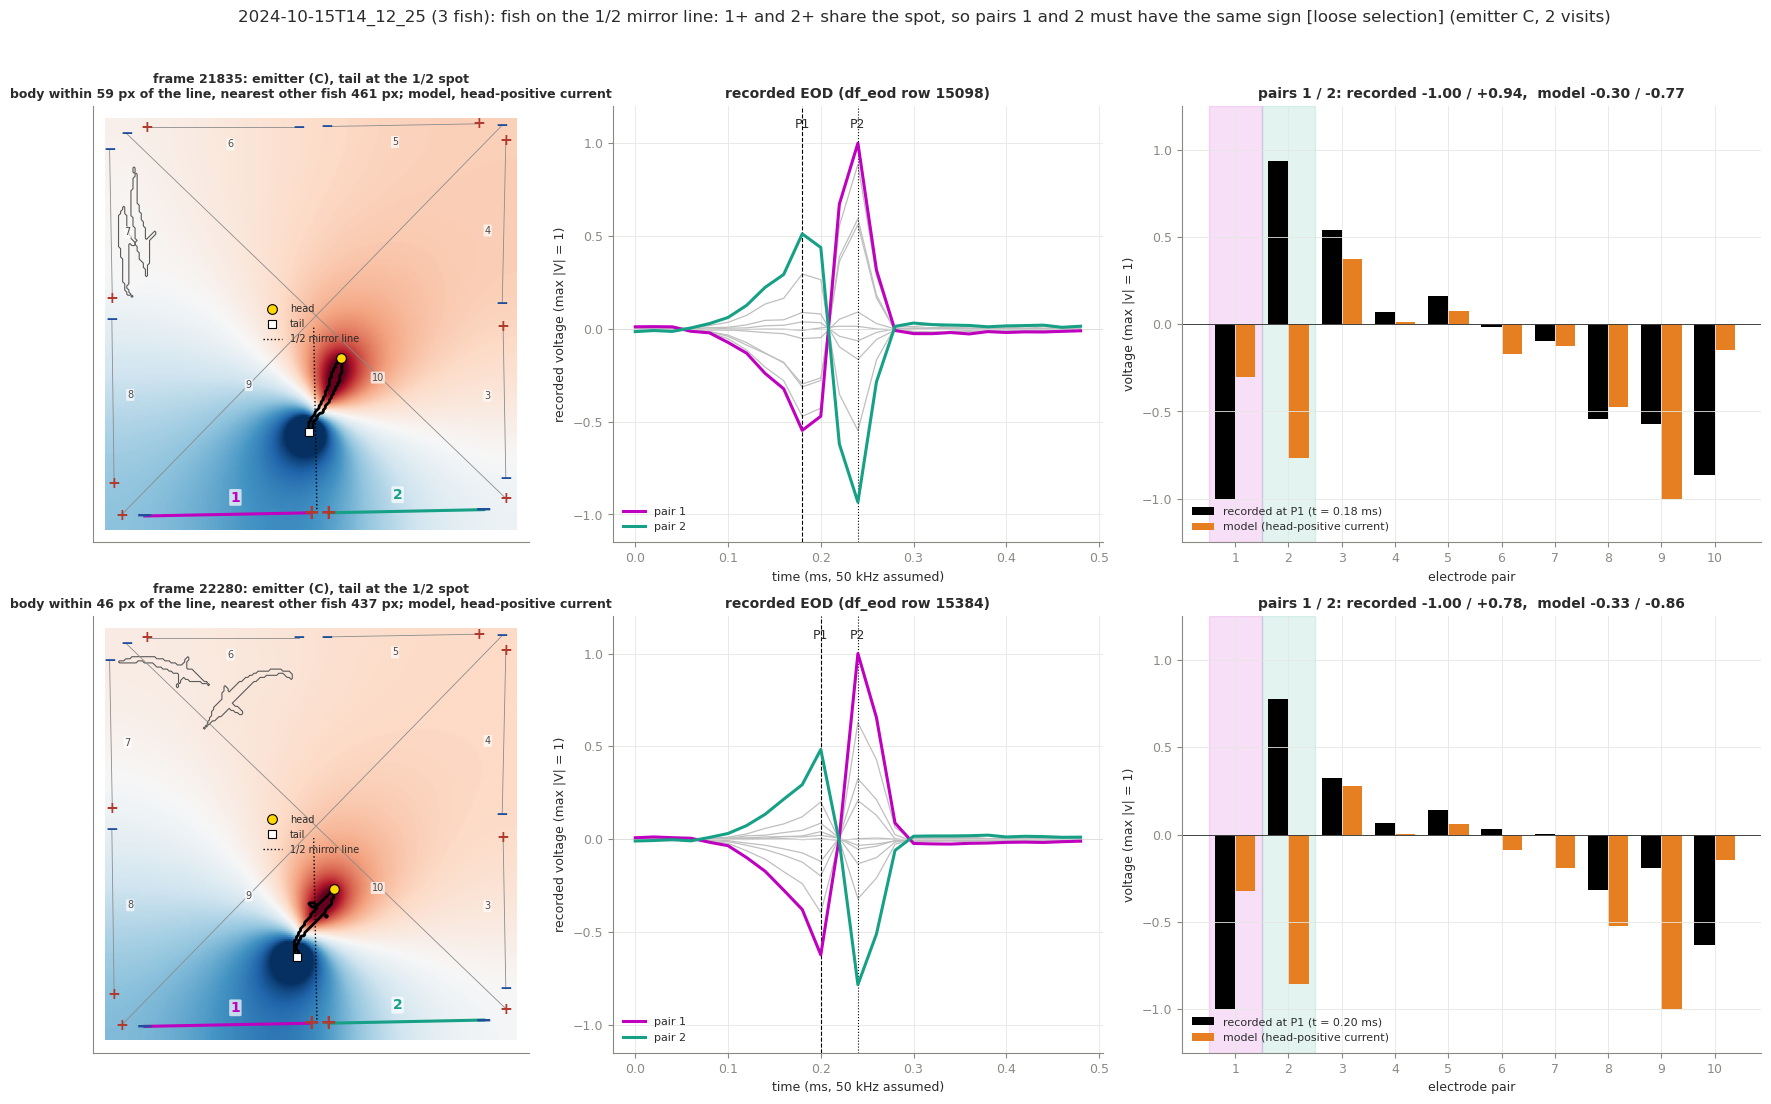

pairs 2/3: no symmetric EOD of fish C with the loose selection


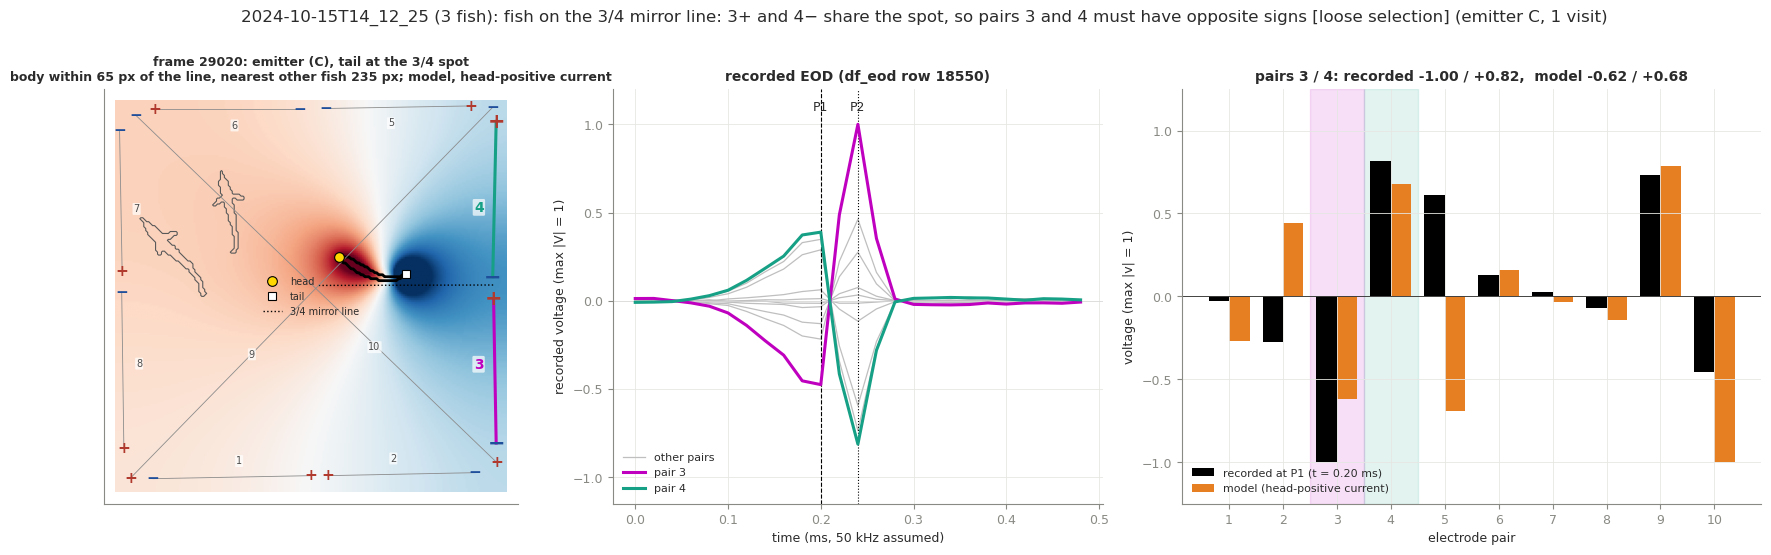

pairs 4/5: no symmetric EOD of fish C with the loose selection


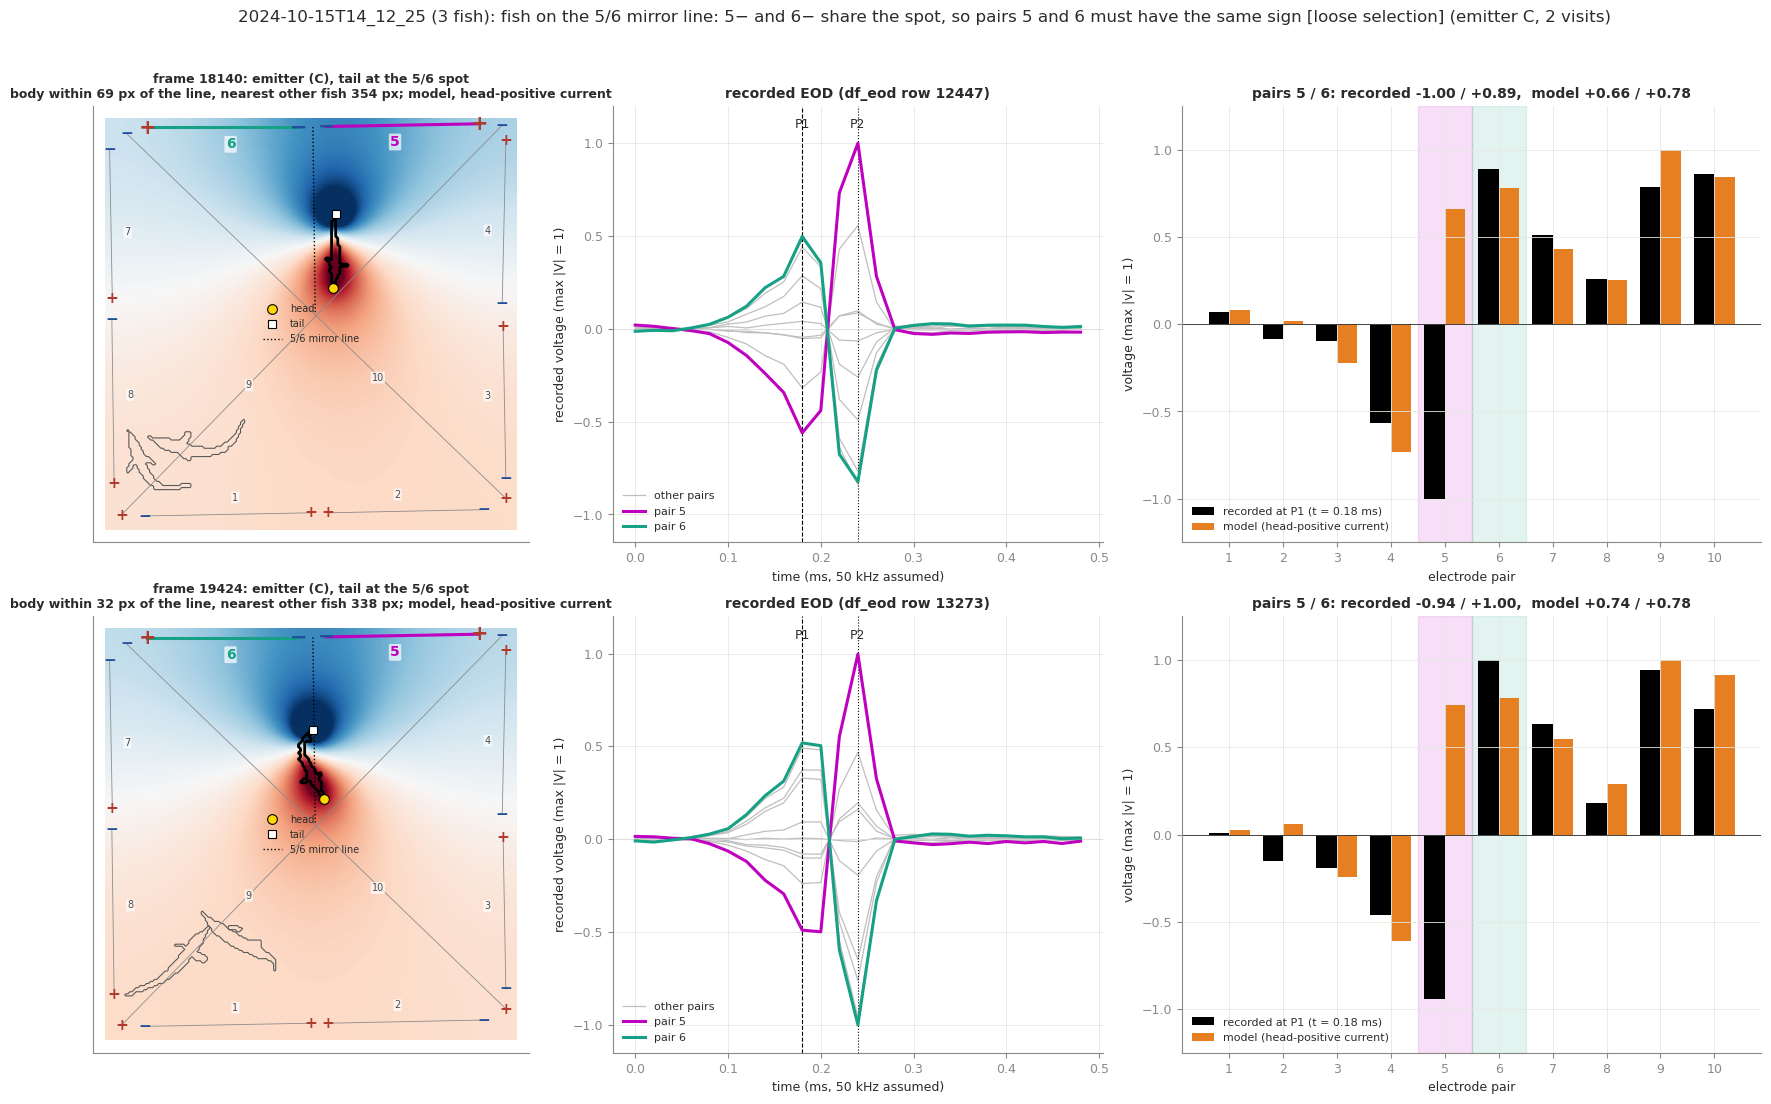

pairs 6/7: no symmetric EOD of fish C with the loose selection
pairs 7/8: no symmetric EOD of fish C with the loose selection
pairs 8/1: no symmetric EOD of fish C with the loose selection


In [9]:
shown_loose = []
for pa, pb in SPOTS:
    if ((sym4L.pa == pa) & (sym4L.pb == pb)).any():
        shown_loose += show_spot(R4, sym4L, pa, pb, spot_title(pa, pb) + ' [loose selection]')
    else:
        print(f'pairs {pa}/{pb}: no symmetric EOD of fish C with the loose selection')

## 6. All example frames and saved tables

In [10]:
ex = pd.concat([pd.DataFrame(shown).assign(selection='4-fish keypoint thresholds'),
                pd.DataFrame(shown_loose).assign(selection='loose keypoint thresholds')], ignore_index=True)
if len(ex):
    rule = {f'{a}/{b}': ('same' if mirror_line(a, b)[2][0] == mirror_line(a, b)[2][1] else 'opposite') for a, b in SPOTS}
    ex['rule'] = ex.pairs.map(rule)
    ex['recorded signs'] = np.where(np.sign(ex.rec_a) == np.sign(ex.rec_b), 'same', 'opposite')
    ex['follows labels'] = ex['recorded signs'] == ex.rule
display(ex)
OUT = 'results/eod_ground_truth_3fish'
ex.to_csv(f'{OUT}/polarity_mirror_3fish_examples.csv', index=False)
pd.concat({**{f'2024-02-13, {k}': v for k, v in tables.items()}, **{f'2024-10-23, {k}': v for k, v in tables_oct.items()},
           **tables_loose}, axis=1).to_csv(f'{OUT}/polarity_mirror_3fish_spots.csv')

,recording,row,frame,pairs,fish,end,head_matches_keypoints,rec_a,rec_b,model_a,model_b,selection,rule,recorded signs,follows labels
0,2024-10-15T14_12_25 (3 fish),18966,32694,5/6,C,tail,True,-1.00,0.73,1.00,0.96,4-fish keypoint thresholds,same,opposite,False
1,2024-10-15T14_12_25 (3 fish),15098,21835,1/2,C,tail,True,-1.00,0.94,-0.30,-0.77,loose keypoint thresholds,same,opposite,False
2,2024-10-15T14_12_25 (3 fish),15384,22280,1/2,C,tail,True,-1.00,0.78,-0.33,-0.86,loose keypoint thresholds,same,opposite,False
3,2024-10-15T14_12_25 (3 fish),18550,29020,3/4,C,tail,True,-1.00,0.82,-0.62,0.68,loose keypoint thresholds,opposite,opposite,True
4,2024-10-15T14_12_25 (3 fish),12447,18140,5/6,C,tail,True,-1.00,0.89,0.66,0.78,loose keypoint thresholds,same,opposite,False
5,2024-10-15T14_12_25 (3 fish),13273,19424,5/6,C,tail,True,-0.94,1.00,0.74,0.78,loose keypoint thresholds,same,opposite,False
